<a href="https://colab.research.google.com/github/Hamsamohsen/Plastic-AI-sorting-system-/blob/main/ai_training_3%20final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
from google.colab import drive

drive.mount('/content/drive')

# مسار ملف الـ Zip على درايف ومسار الفك في كولاب
zip_path = '/content/drive/MyDrive/Database cap.zip'
extract_path = '/content/dataset'

if not os.path.exists(extract_path):
  os.makedirs(extract_path)
  print('...جاري فك ضغط الداتاسيت، يرجى الانتظار')
  !unzip -q "{zip_path}" -d "{extract_path}"
  print('!تم فك الضغط بنجاح')
else:
  print('ملفات الداتاسيت مفكوكة مسبقاً وجاهزة')

Mounted at /content/drive
...جاري فك ضغط الداتاسيت، يرجى الانتظار
!تم فك الضغط بنجاح


In [2]:
import os
import shutil

base_cap_dir = '/content/dataset/Database cap/Cap'
clean_dir = '/content/clean_dataset'

os.makedirs(clean_dir, exist_ok=True)
classes = ['PET', 'others', 'HDPE', 'PP']

print('...جاري تجميع وترتيب الصور في مجلد نظيف')
for cls in classes:
  cls_dest = os.path.join(clean_dir, cls)
  os.makedirs(cls_dest, exist_ok=True)
  cls_src = os.path.join(base_cap_dir, cls)

  if os.path.exists(cls_src):
    count = 0
    for root, dirs, files in os.walk(cls_src):
      for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp')):
          src_file = os.path.join(root, file)
          dst_file = os.path.join(cls_dest, file)
          if os.path.exists(dst_file):
            base_name, ext = os.path.splitext(file)
            dst_file = os.path.join(cls_dest, f'{base_name}_{count}{ext}')
          shutil.copy(src_file, dst_file)
          count += 1
    print(f'تم بنجاح تجميع {count} صورة لفئة {cls}')

print('\n!انتهى الترتيب وأصبح المجلد جاهزاً للتدريب')

...جاري تجميع وترتيب الصور في مجلد نظيف
تم بنجاح تجميع 617 صورة لفئة PET
تم بنجاح تجميع 451 صورة لفئة others
تم بنجاح تجميع 607 صورة لفئة HDPE
تم بنجاح تجميع 492 صورة لفئة PP

!انتهى الترتيب وأصبح المجلد جاهزاً للتدريب


In [3]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

IMG_SIZE = 224
BATCH_SIZE = 32
DATASET_PATH = '/content/clean_dataset'

# تحميل بيانات التدريب مع ضمان تحويل كل الصور لـ RGB (3 قنوات) تلقائياً
train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    color_mode='rgb' # <--- دي بتجبر أي صورة تتظبط وتكون 3 قنوات RGB
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    color_mode='rgb' # <--- نفس الكلام هنا
)

class_names = train_dataset.class_names
print("Class Names Order:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.prefetch(buffer_size=AUTOTUNE)

Found 2117 files belonging to 4 classes.
Using 1694 files for training.
Found 2117 files belonging to 4 classes.
Using 423 files for validation.
Class Names Order: ['HDPE', 'PET', 'PP', 'others']


In [4]:

import os
from PIL import Image

clean_dir = '/content/clean_dataset'

print('...جاري فحص وتصفية الصور للتأكد من توافق القنوات (RGB)')
count_fixed = 0
count_removed = 0

for root, dirs, files in os.walk(clean_dir):
  for file in files:
    if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp')):
      file_path = os.path.join(root, file)
      try:
        # التحقق من سلامة الصورة
        with Image.open(file_path) as img:
          img.verify()

        # إعادة فتحها وتعديل القنوات لو مش RGB
        with Image.open(file_path) as img:
          if img.mode != 'RGB':
            img = img.convert('RGB')
            img.save(file_path)
            count_fixed += 1
      except Exception as e:
        # لو الصورة تالفة تماماً يتم حذفها لمنع إيقاف التدريب
        if os.path.exists(file_path):
          os.remove(file_path)
          count_removed += 1

print(f'تم الانتهاء! تم تعديل {count_fixed} صورة، وحذف {count_removed} صورة تالفة.')

...جاري فحص وتصفية الصور للتأكد من توافق القنوات (RGB)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


تم الانتهاء! تم تعديل 36 صورة، وحذف 0 صورة تالفة.


In [5]:
# 1. إعداد طبقات الـ Data Augmentation لمواجهة اختلاف الإضاءة والزوايا
data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.2),
        layers.RandomContrast(0.2),
        layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    ],
    name="data_augmentation",
)

# 2. تحميل نموذج MobileNetV2 الأساسي
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet"
)
base_model.trainable = False  # تجميد الأوزان الأساسية في المرحلة الأولى

# 3. تجميع هيكل الموديل الكامل
model = tf.keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    data_augmentation,  # تُطبق تلقائياً أثناء التدريب فقط
    layers.Rescaling(1.0 / 127.5, offset=-1),  # التحجيم القياسي لـ MobileNetV2 (-1 إلى 1)
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [6]:
# المرحلة الأولى: تدريب الطبقات العليا
EPOCHS = 15
history = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS)

# المرحلة الثانية: Fine-Tuning لزيادة دقة التمييز بين HDPE و PP
base_model.trainable = True
for layer in base_model.layers[:-30]:  # تجميد كل الطبقات ما عدا آخر 30 طبقة
  layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),  # معدل تعلم صغير جداً للحفاظ على الدقة
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

FINE_TUNE_EPOCHS = 10
history_fine = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS + FINE_TUNE_EPOCHS,
    initial_epoch=history.epoch[-1],
)

Epoch 1/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 135s 2s/step - accuracy: 0.6541 - loss: 0.9124 - val_accuracy: 0.7896 - val_loss: 0.5834
Epoch 2/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 128s 2s/step - accuracy: 0.7845 - loss: 0.5746 - val_accuracy: 0.8061 - val_loss: 0.5203
Epoch 3/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 146s 3s/step - accuracy: 0.8064 - loss: 0.5060 - val_accuracy: 0.8463 - val_loss: 0.4535
Epoch 4/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 136s 2s/step - accuracy: 0.8383 - loss: 0.4492 - val_accuracy: 0.8274 - val_loss: 0.4516
Epoch 5/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 127s 2s/step - accuracy: 0.8459 - loss: 0.4022 - val_accuracy: 0.8322 - val_loss: 0.4518
Epoch 6/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 126s 2s/step - accuracy: 0.8518 - loss: 0.4001 - val_accuracy: 0.8298 - val_loss: 0.4599
Epoch 7/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 143s 2s/step - accuracy: 0.8607 - loss: 0.3778 - val_accuracy: 0.8440 - val_loss: 0.4329
Epoch 8/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 143s 2s/step - accuracy: 0.8524 - loss: 0.3597 - val_accuracy: 0.8558 - v

              precision    recall  f1-score   support

        HDPE       0.92      0.90      0.91       126
         PET       0.95      0.88      0.91       126
          PP       0.92      0.78      0.84       100
      others       0.62      0.86      0.72        71

    accuracy                           0.86       423
   macro avg       0.85      0.85      0.85       423
weighted avg       0.88      0.86      0.86       423



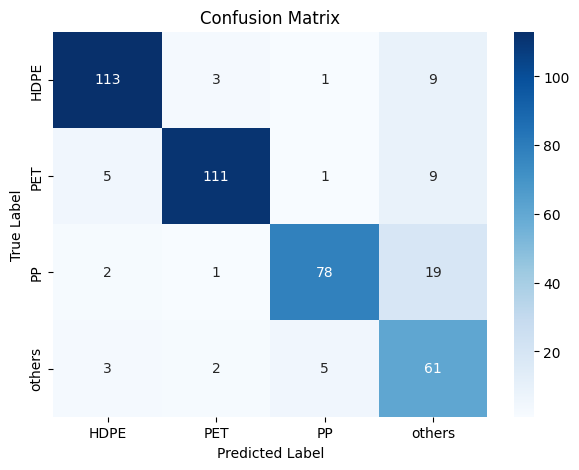

In [7]:
y_true = []
y_pred_classes = []

for images, labels in val_dataset:
  preds = model.predict(images, verbose=0)
  y_pred_classes.extend(np.argmax(preds, axis=1))
  y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred_classes = np.array(y_pred_classes)

print(classification_report(y_true, y_pred_classes, target_names=class_names))

plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_true, y_pred_classes)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [8]:
# تحويل الموديل إلى TFLite مع تفعيل الضغط القياسي (Quantization Optimization)
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

# حفظ الملف
model_file_name = "plastic_sorting_model.tflite"
with open(model_file_name, 'wb') as f:
    f.write(tflite_model)

print(f"تم ضغط وتحويل الموديل وحفظه باسم: {model_file_name} بنجاح!")

# تنزيل الملف مباشرة لجهازك المحلي
from google.colab import files
files.download(model_file_name)

Saved artifact at '/tmp/tmp0n4ikc4o'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  132857554276176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132857554276944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132857554276752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132857554277136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132857554272336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132857554276368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132857554277904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132857554277712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132857554278096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132857554275984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1328575542

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>